<div style="font-size: 2em; font-weight: bold; margin-top: 0.67em; margin-bottom: 0.67em;">
UE L2 Projet de Statistique CMI OSIA
</div>
<a href="https://www.u-bordeaux.fr/">
    <img src="https://upload.wikimedia.org/wikipedia/commons/e/e9/Universität_Bordeaux_Logo.svg?utm_source=fr.wikipedia.org&utm_campaign=index&utm_content=original"
         style="max-width: 180px; display: inline"
         alt="Université de Bordeaux"/>
</a>
<div style="font-size: 1em; font-weight: bold; margin-top: 0.67em; margin-bottom: 0.67em;">
Année 2026-2027
</div>
<div style="color: blue; font-size: 1.5em; font-weight: bold; margin-top: 0.67em; margin-bottom: 0.67em;">
Défi Science des données - Prévision de disponibilité de vélos dans des stations en libre service
</div>

<a href="https://www.python.org/">
    <img src="https://www.python.org/static/community_logos/python-logo.png"
         style="max-width: 180px; display: inline"
         alt="Python"/>
</a>

Cette UE est organisée sous la forme d'un défi en science des données qui propose l'utilisation de librairies en ``Python`` pour le traitement de données et l'implémentation de modèles statistiques pour une tâche d'apprentissage automatique de la prévision du nombre de vélos disponibles dans des stations en libre service dans différentes villes.

Dans ce projet, vous allez apprendre à :

- réaliser des analyses de statistique descriptive d'un jeu de données réelles de grande taille,
- concevoir différents modèles statistiques de prévisions de données temporelles et spatiales,
- mettre en place les principes de base de l'apprentissage statistique,
- implémenter des algorithmes de prévision et comparer leurs performances.

Les attendus du projet, qui est à réaliser en binôme, sont :

- un compte-rendu en .pdf qui présente votre démarche statistique, vos résultats de statistique descriptive des données, ainsi que les meilleurs modèles que vous avez retenus et leur validation à l'aide des données disponibles,

- un notebook Jupyter qui donne un code sous forme commentée conduisant à votre meilleur modèle,

- une soutenance orale de présentation des résultats de votre projet.

<div style="font-size: 2em; font-weight: bold; margin-top: 0.67em; margin-bottom: 0.67em;">
Prise en main des données
</div>

Les données de ce projet ont été collectées dans la ville de Toulouse par Max Halford, data scientist formé à l'Université de Toulouse : https://maxhalford.github.io

Ces données sont relatives au  nombre de vélos disponibles dans des stations de vélos en libre service, et elles ont été collectées sur plusieurs années de 2023 à 2026. Il s'agit d'un exemple d'un jeu de données ouvertes collectées en ligne. Les données ont été stockées dans des fichiers Parquet qui est un format de stockage très utilisé en Python pour la science des données. Pour ce projet vous avez accès à 4 fichiers :

- ``stations_toulouse.parquet`` qui contient la liste des stations où des données ont pu être collectées avec l'information sur leur nom et leur localisation géographique

- ``history_toulouse_train.parquet`` qui contient les données qui constituent la base d'apprentissage du défi. Ce fichier contient, pour chaque station où des mesures ont pu être réalisées, le nombre de vélos disponibles toutes les 15mn sur une plage de temps qui peut varier d'une station à l'autre

- ``history_toulouse_test.parquet`` qui contient les stations et les dates pour lesquelles vous devez faire des prévisions. Pour chaque station dans la base d'apprentissage, il est demandé de prévoir le nombre de vélos toutes les 15mn sur les 2 prochaines heures qui suivent la dernière date (jour/heure) de collecte de données, soit 8 prévisions à effectuer pour chaque station. 

<div style="font-size: 1em; font-weight: bold; margin-top: 0.67em; margin-bottom: 0.67em;">
Importation des données
</div>

Le code ci-dessous permet d'importer ces différents fichiers, de visualiser leur contenu ainsi que leur organisation sous forme de DataFrame Pandas.

**Noms et coordonnées des stations**

In [3]:
import pandas as pd

stations_toulouse = pd.read_parquet("stations_toulouse.parquet")
stations_toulouse

,station,longitude,latitude,station_id
0,00001 - POIDS DE L'HUILE,1.445475,43.604190,0
1,00002 - LAFAYETTE,1.445306,43.604885,1
2,00003 - ALSACE - LORRAINE - POMME,1.445454,43.603302,2
3,00003 - ALSACE-LORRAINE - POMME,1.445454,43.603302,3
4,00003 - POMME,1.445454,43.603302,4
...,...,...,...,...
858,TOLOSANE - PASTOURELLES,1.477417,43.543115,858
859,TOLOSANE - POUCIQUOT,1.469875,43.551101,859
860,TOURNEFEUILLE MAIRIE,1.346042,43.583665,860
861,VELASQUEZ - TAMARIS,1.390347,43.621004,861


**Données d'entrainement**

``history_toulouse_train`` dans le code ci-dessous est un DataFrame Pandas, avec :
- des lignes identifiées par un MultiIndex (nom de la station et date de mesure)
- des colonnes nommées ``bikes`` et ``stands``qui contiennent respectivement le nombre de vélos disponibles et le nombre de vélos manquants pour une station et une date (jour/heure) données

In [4]:
history_toulouse_train = pd.read_parquet("history_toulouse_train.parquet")
history_toulouse_train

bikes  stands
station                  commit_at                         
00001 - POIDS DE L'HUILE 2023-08-05 12:15:00     10       9
                         2023-08-05 12:30:00     10       9
                         2023-08-05 12:45:00     10       9
                         2023-08-05 13:00:00     11       8
                         2023-08-05 13:15:00     11       8
...                                             ...     ...
TEST BEE                 2026-02-12 15:00:00      0       3
                         2026-02-12 15:15:00      0       3
                         2026-02-12 15:30:00      0       3
                         2026-02-12 15:45:00      0       3
                         2026-02-12 16:00:00      0       3

[40012622 rows x 2 columns]

In [8]:
print(history_toulouse_train.index.dtypes)

station                 str
commit_at    datetime64[us]
dtype: object


**Données de test**

``history_toulouse_test`` dans le code ci-dessous est un DataFrame Pandas, avec :
- des lignes identifiées par un MultiIndex (une station à la date de la dernière mesure faite dans les données d'entraînement)
- des colonnes nommées ``bikes_+15min``,...,``bikes_+120min`` qui doivent être complétées par des prévisions tous les 15 minutes pendant 2 heures

In [11]:
history_toulouse_test = pd.read_parquet("history_toulouse_test.parquet")
history_toulouse_test

,horizon,bikes_+15min,bikes_+30min,bikes_+45min,bikes_+60min,bikes_+75min,bikes_+90min,bikes_+105min,bikes_+120min
station,commit_at,,,,,,,,
00001 - POIDS DE L'HUILE,2026-07-31 21:45:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
00002 - LAFAYETTE,2026-07-31 23:45:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
00003 - ALSACE - LORRAINE - POMME,2025-11-10 11:45:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
00003 - ALSACE-LORRAINE - POMME,2026-07-31 21:45:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
00003 - POMME,2025-01-05 05:45:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...
NARBONNE - CLOTASSES,2025-08-22 19:15:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PASTEUR - LAVOISIER,2025-08-05 10:15:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PLACE GEORGES BRASSENS,2025-08-05 11:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


<div style="font-size: 2em; font-weight: bold; margin-top: 0.67em; margin-bottom: 0.67em;">
Travail à réaliser
</div>

**Statistique descriptive des données**

- nombre de stations de vélos et affichage sur une carte de leurs positions
- date de début et fin des mesures par stations
- présence de données manquantes ?
- statistique de base par station : maximimum, minimum, moyenne, écart-type, quartiles
- calcul de la courbe moyenne journalière de remplissage d'une station (toutes les 15 minutes), et de l'ensemble des stations / superposition de l'écart-type
- tracé sur une carte de l'évolution temporelle de remplissage moyen de l'ensemble des stations sur une journée -> quelles dynamiques urbaines ?
- autres idées ?...

**Méthode de prévision basiques**

- prévision par la moyenne du nombre de vélos disponibles
- prévision par la moyenne horaire (toutes les 15 mn) du nombre de vélos disponibles
- autres idées ?...
- soumissions de vos prévisions et cacul de l'erreur RMSE sur la partie publique des données de test


**Prévision par apprentissage statistique**

A venir...

<div style="font-size: 2em; font-weight: bold; margin-top: 0.67em; margin-bottom: 0.67em;">
Manipulation et visualisation des données
</div>

On présente ci-dessous quelques manipulations élémentaires et procédures de visualisation des données d'entraînement

In [5]:
install pip


SyntaxError: invalid syntax (2795319350.py, line 1)

In [6]:
# pip install folium
import folium

# Centre de la carte = moyenne des coordonnées
center_lat = stations_toulouse["latitude"].mean()
center_lon = stations_toulouse["longitude"].mean()

m = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=12
)

# Ajouter les stations
for _, row in stations_toulouse.iterrows():
    folium.Marker(
        location=[row["latitude"], row["longitude"]],
        popup=f"Station ID : {row['station']}",
        tooltip=f"Station {row['station']}"
    ).add_to(m)

m

ModuleNotFoundError: No module named 'folium'

In [18]:
# Nom d'une station que l'on souhaite étudier
station = "00001 - POIDS DE L'HUILE"

# Sélection de toutes les observations de cette station
donnees_station = history_toulouse_train.loc[station]

Ici, ``.loc[station]`` permet de sélectionner les lignes correspondant à une valeur du premier niveau du MultiIndex (``station``).
On obtient alors un DataFrame dont l'index est uniquement commit_at

In [19]:
print(donnees_station)

                     bikes  stands
commit_at                         
2023-08-05 12:15:00     10       9
2023-08-05 12:30:00     10       9
2023-08-05 12:45:00     10       9
2023-08-05 13:00:00     11       8
2023-08-05 13:15:00     11       8
...                    ...     ...
2026-07-31 20:45:00      1      15
2026-07-31 21:00:00      1      15
2026-07-31 21:15:00      1      15
2026-07-31 21:30:00      9       7
2026-07-31 21:45:00      9       7

[104775 rows x 2 columns]


In [9]:
# Récupérer uniquement les vélos disponibles

# On sélectionne la colonne "bikes"
bikes_station = donnees_station["bikes"]

print(bikes_station)

commit_at
2023-08-05 12:15:00    10
2023-08-05 12:30:00    10
2023-08-05 12:45:00    10
2023-08-05 13:00:00    11
2023-08-05 13:15:00    11
                       ..
2026-07-31 20:45:00     1
2026-07-31 21:00:00     1
2026-07-31 21:15:00     1
2026-07-31 21:30:00     9
2026-07-31 21:45:00     9
Name: bikes, Length: 104775, dtype: uint8


In [10]:
# Idem
bikes_station = history_toulouse_train.loc[station, "bikes"]
print(bikes_station)

commit_at
2023-08-05 12:15:00    10
2023-08-05 12:30:00    10
2023-08-05 12:45:00    10
2023-08-05 13:00:00    11
2023-08-05 13:15:00    11
                       ..
2026-07-31 20:45:00     1
2026-07-31 21:00:00     1
2026-07-31 21:15:00     1
2026-07-31 21:30:00     9
2026-07-31 21:45:00     9
Name: bikes, Length: 104775, dtype: uint8


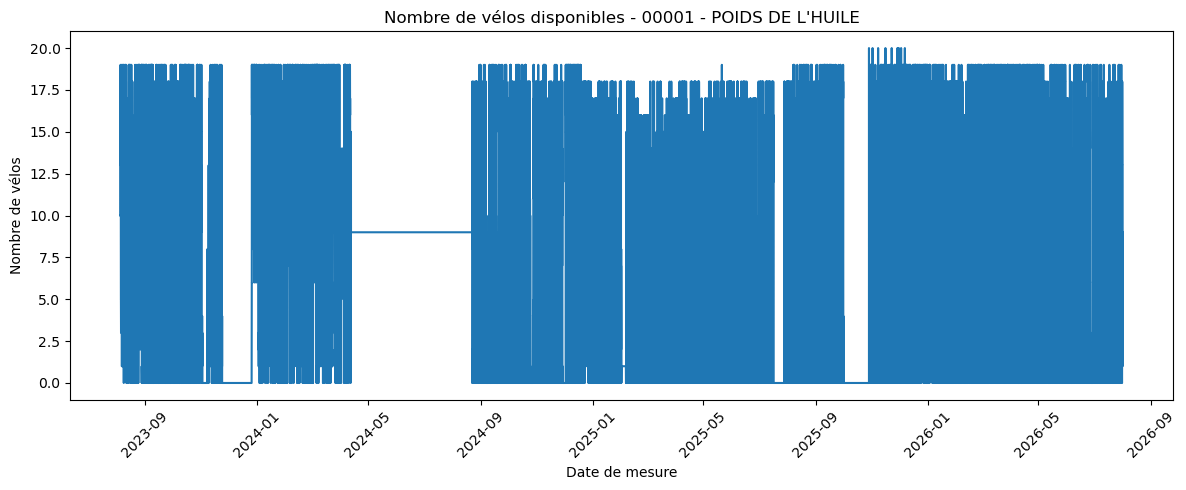

In [11]:
# Tracer le nombre de vélos au cours du temps

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    bikes_station.index,   # les dates de mesure
    bikes_station.values   # le nombre de vélos
)

plt.xlabel("Date de mesure")
plt.ylabel("Nombre de vélos")
plt.title(f"Nombre de vélos disponibles - {station}")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [16]:
import numpy as np

help(np.round)

Help on _ArrayFunctionDispatcher in module numpy:

round(a, decimals=0, out=None)
    Evenly round to the given number of decimals.

    Parameters
    ----------
    a : array_like
        Input data.
    decimals : int, optional
        Number of decimal places to round to (default: 0).  If
        decimals is negative, it specifies the number of positions to
        the left of the decimal point.
    out : ndarray, optional
        Alternative output array in which to place the result. It must have
        the same shape as the expected output, but the type of the output
        values will be cast if necessary. See :ref:`ufuncs-output-type`
        for more details.

    Returns
    -------
    rounded_array : ndarray
        An array of the same type as `a`, containing the rounded values.
        Unless `out` was specified, a new array is created.  A reference to
        the result is returned.

        The real and imaginary parts of complex numbers are rounded
        separately

In [13]:
# Moyenne du nombre de vélos pour une station
moyenne_bikes = np.round(bikes_station.mean())

print(f"Nombre moyen de vélos : {moyenne_bikes:.2f}")

Nombre moyen de vélos : 6.00


In [ ]:
# Autre statistiques
print(bikes_station.min())     # minimum
print(bikes_station.max())     # maximum
print(bikes_station.median())  # médiane
print(bikes_station.sum())     # somme
print(bikes_station.count())   # nombre de mesures
ecart_type_bikes = bikes_station.std()
print(f"Ecart-type : {ecart_type_bikes:.2f}")

In [17]:
# Récupérer une mesure à une date donnée

station = "00001 - POIDS DE L'HUILE"
date = "2025-01-01 08:00:00"

try:
    mesure = history_toulouse_train.loc[(station, date)]

    print("Mesure trouvée :")
    print(mesure)

except KeyError:
    print(f"Aucune mesure disponible pour la station '{station}' "
          f"à la date {date}.")

date = "2020-01-01 08:00:00"

try:
    mesure = history_toulouse_train.loc[(station, date)]

    print("Mesure trouvée :")
    print(mesure)

except KeyError:
    print(f"Aucune mesure disponible pour la station '{station}' "
          f"à la date {date}.")

Mesure trouvée :
bikes      0
stands    17
Name: (00001 - POIDS DE L'HUILE, 2025-01-01 08:00:00), dtype: uint8
Aucune mesure disponible pour la station '00001 - POIDS DE L'HUILE' à la date 2020-01-01 08:00:00.


In [ ]:
# Les 5 premières observations de la station
donnees_station.head(5) 

In [ ]:
# Les 5 dernières observations de la station
donnees_station.tail(5)

In [15]:
# Utilisation de groupby

# Récupèration de la dernière date de mesure pour chaque station
# des données d'entraînement
last = (
    history_toulouse_train
    .groupby(level="station")
    .tail(1)
    .copy()
)

last

,,bikes,stands
station,commit_at,,
00001 - POIDS DE L'HUILE,2026-07-31 21:45:00,9,7
00002 - LAFAYETTE,2026-07-31 23:45:00,9,9
00003 - ALSACE - LORRAINE - POMME,2025-11-10 11:45:00,18,0
00003 - ALSACE-LORRAINE - POMME,2026-07-31 21:45:00,12,4
00003 - POMME,2025-01-05 05:45:00,17,0
...,...,...,...
NARBONNE - CLOTASSES,2025-08-22 19:15:00,0,16
PASTEUR - LAVOISIER,2025-08-05 10:15:00,0,0
PLACE GEORGES BRASSENS,2025-08-05 11:00:00,0,0


In [12]:
history_toulouse_naive = history_toulouse_test.copy()
history_toulouse_naive

,horizon,bikes_+15min,bikes_+30min,bikes_+45min,bikes_+60min,bikes_+75min,bikes_+90min,bikes_+105min,bikes_+120min
station,commit_at,,,,,,,,
00001 - POIDS DE L'HUILE,2026-07-31 21:45:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
00002 - LAFAYETTE,2026-07-31 23:45:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
00003 - ALSACE - LORRAINE - POMME,2025-11-10 11:45:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
00003 - ALSACE-LORRAINE - POMME,2026-07-31 21:45:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
00003 - POMME,2025-01-05 05:45:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...
NARBONNE - CLOTASSES,2025-08-22 19:15:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PASTEUR - LAVOISIER,2025-08-05 10:15:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PLACE GEORGES BRASSENS,2025-08-05 11:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
mean_bikes_station = (
    history_toulouse_train
    .groupby(level="station")["bikes"]
    .mean()
    .round()
)

print(mean_bikes_station.head())
print(len(mean_bikes_station))

station
00001 - POIDS DE L'HUILE              6.0
00002 - LAFAYETTE                    10.0
00003 - ALSACE - LORRAINE - POMME     4.0
00003 - ALSACE-LORRAINE - POMME       6.0
00003 - POMME                        10.0
Name: bikes, dtype: float64
800


In [15]:
target_columns = [
    "bikes_+15min",
    "bikes_+30min",
    "bikes_+45min",
    "bikes_+60min",
    "bikes_+75min",
    "bikes_+90min",
    "bikes_+105min",
    "bikes_+120min"
]

In [16]:
# Station correspondant à chaque ligne du template
stations_a_predire = history_toulouse_naive.index.get_level_values("station")
print(stations_a_predire)

Index(['00001 - POIDS DE L'HUILE', '00002 - LAFAYETTE',
       '00003 - ALSACE - LORRAINE - POMME', '00003 - ALSACE-LORRAINE - POMME',
       '00003 - POMME', '00004 - GAMBETTA - SAINTE - URSULE',
       '00004 - GAMBETTA - SAINTE-URSULE', '00004 - GAMBETTA - STE-URSULE',
       '00004 - SAINTE-URSULE', '00005 - LEDUC',
       ...
       '9005 - ALLENDE - ADOUR', '9006 - MAROTS - TINEE', 'BRUNAUD - CEAT',
       'CAYRAS –CATALA', 'MONT LOUIS –AV. DE TOULOUSE', 'NARBONNE - CLOTASSES',
       'PASTEUR - LAVOISIER', 'PLACE GEORGES BRASSENS',
       'SERVANTY AIRBUS TRAMWAY', 'TEST BEE'],
      dtype='object', name='station', length=800)


In [17]:
print(stations_a_predire[798])
station = stations_a_predire[798]

history_train_station = (
    history_toulouse_train
    .loc[station]
)

print(history_train_station)

history_test_station = (
    history_toulouse_test
    .loc[station]
)

print(history_test_station)

SERVANTY AIRBUS TRAMWAY
                     bikes  stands
commit_at                         
2025-07-29 09:15:00      0       0
2025-07-29 09:30:00      0       0
2025-07-29 09:45:00      0       0
2025-07-29 10:00:00      0       0
2025-07-29 10:15:00      0       0
...                    ...     ...
2025-08-01 11:15:00      0      16
2025-08-01 11:30:00      0      16
2025-08-01 11:45:00      0      16
2025-08-01 12:00:00      0      16
2025-08-01 12:15:00      0      16

[301 rows x 2 columns]
horizon              bikes_+15min  bikes_+30min  bikes_+45min  bikes_+60min  \
commit_at                                                                     
2025-08-01 12:15:00           NaN           NaN           NaN           NaN   

horizon              bikes_+75min  bikes_+90min  bikes_+105min  bikes_+120min  
commit_at                                                                      
2025-08-01 12:15:00           NaN           NaN            NaN            NaN  


In [18]:
# Moyenne historique de chaque station à prédire
predictions = mean_bikes_station.reindex(stations_a_predire)

In [19]:
predictions

station
00001 - POIDS DE L'HUILE              6.0
00002 - LAFAYETTE                    10.0
00003 - ALSACE - LORRAINE - POMME     4.0
00003 - ALSACE-LORRAINE - POMME       6.0
00003 - POMME                        10.0
                                     ... 
NARBONNE - CLOTASSES                  0.0
PASTEUR - LAVOISIER                   0.0
PLACE GEORGES BRASSENS                0.0
SERVANTY AIRBUS TRAMWAY               0.0
TEST BEE                              1.0
Name: bikes, Length: 800, dtype: float64

In [ ]:
predictions.to_numpy()[:, None][0:5]

In [ ]:
# Remplissage des 8 horizons avec la même moyenne
history_toulouse_naive.loc[:, target_columns] = (
    predictions.to_numpy()[:, None]
)

In [ ]:
history_toulouse_naive

In [ ]:
history_toulouse_naive.to_parquet("history_toulouse_naive.parquet", index=True)

In [ ]:
# Comparaison avec les données de test
history_toulouse_test

In [ ]:
# Date de la première mesure par station
first = (
    history_toulouse_train
    .groupby(level="station")
    .head(1)
)
first

In [ ]:
premieres_dates = first.index.get_level_values("commit_at")
dernieres_dates = last.index.get_level_values("commit_at")

In [ ]:
premieres_dates

In [ ]:
dernieres_dates

In [ ]:
# Calcul du maximum de vélos disponibles par station
max_velos = (
    history_toulouse_train
    .groupby(level="station")
    .max()
    .copy()
)

max_velos

In [ ]:
# Pour chaque station, on récupère son nombre maximum de vélos
max_bikes = max_velos["bikes"]

print(max_bikes.head())

In [ ]:
max_bikes = max_velos["bikes"]

stations_toulouse["nombre_max_velos"] = (
    stations_toulouse["station"].map(max_bikes)
)

In [ ]:
stations_toulouse

**Ajout du nombre maximum de vélos à chaque station avec `map()`**

Nous disposons de deux structures de données.

`stations_toulouse` est un DataFrame dans lequel le nom de la station est une **colonne** :

```python
stations_toulouse["station"]
```

Par exemple :

```text
0    00001 - POIDS DE L'HUILE
1    00002 - LAFAYETTE
2    00003 - ALSACE - LORRAINE - POMME
...
```

De son côté, `max_velos` est un DataFrame obtenu en regroupant les données par station :

```python
max_velos = (
    history_toulouse_train
    .groupby(level="station")
    .max()
)
```

Dans `max_velos`, le nom de la station n'est **pas une colonne** : c'est l'**index** du DataFrame :

```text
                                   bikes    stands
station
00001 - POIDS DE L'HUILE              20       19
00002 - LAFAYETTE                     25       24
00003 - ALSACE - LORRAINE - POMME     20       18
00003 - ALSACE-LORRAINE - POMME       19       18
00003 - POMME                          18       28
...
```

Lorsque nous écrivons :

```python
max_bikes = max_velos["bikes"]
```

nous sélectionnons uniquement la colonne `bikes`.

**`max_bikes` est alors une Series Pandas**, et non un DataFrame. Elle conserve l'index de `max_velos`, c'est-à-dire le nom des stations :

```text
station
00001 - POIDS DE L'HUILE              20
00002 - LAFAYETTE                     25
00003 - ALSACE - LORRAINE - POMME     20
00003 - ALSACE-LORRAINE - POMME       19
00003 - POMME                          18
...
Name: bikes, dtype: uint8
```

On peut voir cette structure comme un **dictionnaire** :

```text
nom de la station  →  nombre maximum de vélos

POIDS DE L'HUILE   →  20
LAFAYETTE          →  25
ALSACE - ...       →  20
...
```

La méthode `.map()` permet alors de rechercher, pour chaque station de `stations_toulouse`, la valeur correspondante dans `max_bikes` :

```python
stations_toulouse["nombre_max_velos"] = (
    stations_toulouse["station"].map(max_bikes)
)
```

Par exemple, pour la première ligne :

```text
stations_toulouse["station"]
        ↓
"00001 - POIDS DE L'HUILE"
        ↓
recherche dans l'index de max_bikes
        ↓
20
```

La valeur `20` est alors placée dans la nouvelle colonne `nombre_max_velos`.

Ainsi, `.map()` fait une **correspondance par valeur**, et non une correspondance par numéro de ligne. Il n'est donc pas nécessaire que les deux DataFrames soient dans le même ordre.

Une autre façon de voir `.map()` est :

> **Pour chaque valeur de la Series de gauche, chercher cette valeur dans l'index de la Series de droite et récupérer la valeur associée.**

Dans notre exemple :

```python
stations_toulouse["station"].map(max_bikes)
```

signifie :

> « Pour chaque nom de station de `stations_toulouse`, recherche ce nom dans l'index de `max_bikes` et récupère le nombre maximum de vélos correspondant. »

Si une station de `stations_toulouse` n'existe pas dans `max_bikes`, aucune correspondance n'est trouvée et Pandas place `NaN` dans la nouvelle colonne.


In [ ]:
import folium
import branca.colormap as cm

# Carte centrée sur les stations
m = folium.Map(
    location=[
        stations_toulouse["latitude"].mean(),
        stations_toulouse["longitude"].mean()
    ],
    zoom_start=12
)

# Échelle de couleurs basée sur le nombre maximum de vélos
colormap = cm.LinearColormap(
    colors=["blue", "cyan", "yellow", "orange", "red"],
    vmin=stations_toulouse["nombre_max_velos"].min(),
    vmax=stations_toulouse["nombre_max_velos"].max(),
    caption="Nombre maximum de vélos"
)

# Ajouter les stations
for _, row in stations_toulouse.dropna(
    subset=["nombre_max_velos"]
).iterrows():

    folium.CircleMarker(
        location=[row["latitude"], row["longitude"]],
        radius=6,
        color=colormap(row["nombre_max_velos"]),
        fill=True,
        fill_color=colormap(row["nombre_max_velos"]),
        fill_opacity=0.8,
        popup=folium.Popup(
            f"""
            <b>Station :</b> {row['station']}<br>
            <b>ID :</b> {row['station_id']}<br>
            <b>Nombre maximum de vélos :</b>
            {row['nombre_max_velos']}
            """,
            max_width=300
        ),
        tooltip=(
            f"{row['station']} : "
            f"{row['nombre_max_velos']} vélos maximum"
        )
    ).add_to(m)

# Ajouter la légende
colormap.add_to(m)

m

In [ ]:
# Calcul du nombre moyen de vélos disponibles par station
moy_velos = (
    history_toulouse_train
    .groupby(level="station")
    .mean()
    .round()
    .copy()
)

moy_velos


In [ ]:
# Copie du DataFrame
df = history_toulouse_train.copy()

# On récupère le niveau commit_at du MultiIndex
dates = df.index.get_level_values("commit_at")

In [ ]:
dates

In [ ]:
# On crée un nouvel index correspondant uniquement
# à l'heure et aux minutes de la journée.
# Par exemple :
# 2025-01-15 08:15 → 08:15
# 2025-02-20 08:15 → 08:15
# Ces deux observations seront donc regroupées ensemble.
df["heure_minute"] = dates.strftime("%H:%M")
df

In [ ]:
df

In [ ]:
# Moyenne par station et par créneau de 15 minutes
moy_velos_quart_heure = (
    df
    .groupby(["station", "heure_minute"])[["bikes"]]
    .mean()
    .round()
)

moy_velos_quart_heure

In [ ]:
import matplotlib.pyplot as plt

station = "00001 - POIDS DE L'HUILE"

# Sélection de la station
profil_station = moy_velos_quart_heure.loc[station, "bikes"]

# Affichage
plt.figure(figsize=(14, 5))

plt.plot(
    profil_station.index,
    profil_station.values,
    marker="o"
)

plt.xlabel("Heure")
plt.ylabel("Nombre moyen de vélos")
plt.title(f"Nombre moyen de vélos par quart d'heure\n{station}")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.show()

In [ ]:
# Moyenne des stations pour chaque quart d'heure
profil_moyen = (
    moy_velos_quart_heure
    .groupby(level="heure_minute")["bikes"]
    .mean()
)

profil_moyen

In [ ]:
station = "00001 - POIDS DE L'HUILE"

# Profil de la station choisie
profil_station = moy_velos_quart_heure.loc[
    station, "bikes"
]

# Graphique
plt.figure(figsize=(14, 5))

plt.plot(
    profil_station.index,
    profil_station.values,
    marker="o",
    label=station
)

plt.plot(
    profil_moyen.index,
    profil_moyen.values,
    marker="o",
    label="Moyenne de toutes les stations"
)

plt.xlabel("Heure")
plt.ylabel("Nombre moyen de vélos")
plt.title("Profil journalier moyen du nombre de vélos")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [ ]:
# Moyenne et écart type des stations
statistiques_reseau = (
    moy_velos_quart_heure
    .groupby(level="heure_minute")["bikes"]
    .agg(["mean", "std"])
)

statistiques_reseau

In [ ]:
plt.figure(figsize=(14, 5))

x = statistiques_reseau.index
moyenne = statistiques_reseau["mean"]
ecart_type = statistiques_reseau["std"]

# Courbe de la moyenne
plt.plot(
    x,
    moyenne,
    marker="o",
    label="Moyenne des stations"
)

# Zone moyenne ± écart type
plt.fill_between(
    x,
    moyenne - ecart_type,
    moyenne + ecart_type,
    alpha=0.2,
    label="± 1 écart type"
)

plt.xlabel("Heure")
plt.ylabel("Nombre de vélos")
plt.title("Profil journalier moyen du réseau de stations")

plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [ ]:
import folium
import branca.colormap as cm

# Heure que l'on souhaite afficher
heure = "10:30"

# Sélectionner directement les moyennes à cette heure
moyenne_heure = moy_velos_quart_heure.xs(
    heure,
    level="heure_minute"
)["bikes"]

# Associer la moyenne à chaque station
stations_carte = stations_toulouse.copy()

stations_carte["moyenne_velos"] = (
    stations_carte["station"].map(moyenne_heure)
)

# Carte centrée sur les stations
m = folium.Map(
    location=[
        stations_carte["latitude"].mean(),
        stations_carte["longitude"].mean()
    ],
    zoom_start=12
)

# Échelle de couleurs
colormap = cm.LinearColormap(
    colors=["blue", "cyan", "yellow", "orange", "red"],
    vmin=stations_carte["moyenne_velos"].min(),
    vmax=stations_carte["moyenne_velos"].max(),
    caption=f"Nombre moyen de vélos à {heure}"
)

# Ajouter les stations
for _, row in stations_carte.dropna(
    subset=["moyenne_velos"]
).iterrows():

    valeur = row["moyenne_velos"]

    folium.CircleMarker(
        location=[row["latitude"], row["longitude"]],
        radius=6,
        color=colormap(valeur),
        fill=True,
        fill_color=colormap(valeur),
        fill_opacity=0.8,
        popup=folium.Popup(
            f"""
            <b>Station :</b> {row['station']}<br>
            <b>ID :</b> {row['station_id']}<br>
            <b>Heure :</b> {heure}<br>
            <b>Nombre moyen de vélos :</b> {valeur:.0f}
            """,
            max_width=300
        ),
        tooltip=(
            f"{row['station']} : "
            f"{valeur:.0f} vélos en moyenne à {heure}"
        )
    ).add_to(m)

# Ajouter la légende
colormap.add_to(m)

m

In [ ]:
df = history_toulouse_train.copy()

# On extrait l'heure d'enregistrement
df["heure"] = df.index.get_level_values("commit_at").hour

# Moyenne par station et par heure
moy_velos_heure = (
    df
    .groupby(["station", "heure"])[["bikes", "stands"]]
    .mean()
    .round()
)

moy_velos_heure

In [ ]:
station = "00001 - POIDS DE L'HUILE"

In [ ]:
import matplotlib.pyplot as plt

station = "00001 - POIDS DE L'HUILE"

# Sélection de la station
station_data = history_toulouse_train.loc[station].copy()

# Extraction de l'heure à partir de commit_at
station_data["heure"] = station_data.index.hour

station_data

In [ ]:
# Données à représenter :
# une série de valeurs de bikes pour chaque heure
donnees_boxplot = [
    station_data.loc[station_data["heure"] == heure, "bikes"].dropna()
    for heure in range(24)
]
#donnees_boxplot

In [ ]:
# Création du boxplot
plt.figure(figsize=(14, 6))

plt.boxplot(
    donnees_boxplot,
    labels=range(24)
)

plt.xlabel("Heure de la journée")
plt.ylabel("Nombre de vélos disponibles")
plt.title(f"Distribution du nombre de vélos par heure\n{station}")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [ ]:
type(donnees_boxplot)

In [ ]:
donnees_boxplot[0]